# Metacell-level transcriptograms: comparison and divergent systems

The transcriptogram turns each metacell into a **smooth 1-D profile over the ordered proteome** — a
*systems-level embedding* whose coordinates are interpretable (each is a genomic position tied to
specific proteins/pathways). This notebook shows why that is useful for downstream analysis:

1. inspect individual metacell profiles and **compare** them (per cell state);
2. metacell–metacell similarity in systems space;
3. **highly variable systems** — where do metacells diverge most (unsupervised)?
4. a **test for divergent regions** across a grouping (cell state), with interpretable effect sizes.

We reuse the transcriptogram object saved by the main analysis notebook (68 microglial metacells,
5 states, radius 80).

In [1]:
%matplotlib inline
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sctranscriptogramer as sctg

warnings.simplefilter("ignore")
OBJ = Path("/dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/objects")
RES = Path("/dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/results")

tg = ad.read_h5ad(OBJ / "tg_analysis.h5ad")
radius = int(tg.uns["sctg"]["radius"])
present = np.asarray(tg.uns["sctg"]["present_mask"], bool)
pos = tg.var["position"].to_numpy()
emb = np.asarray(tg.layers["transcriptogram"])         # metacells x positions (log2CPM)
print("transcriptogram:", emb.shape, "| present positions:", int(present.sum()), "| radius:", radius)
tg.obs["cell_state"].value_counts()

transcriptogram: (68, 12396) | present positions: 11618 | radius: 80


cell_state
Mic-reduced              17
Homeostatic              16
Neuronal_Surveillance    14
Inflammatory_I           12
Stress_Signature          9
Name: count, dtype: int64

## 1. Individual metacell profiles

Each metacell is a smooth curve along the ordering. Metacells of the same state track each other;
different states peak/dip over different regions.

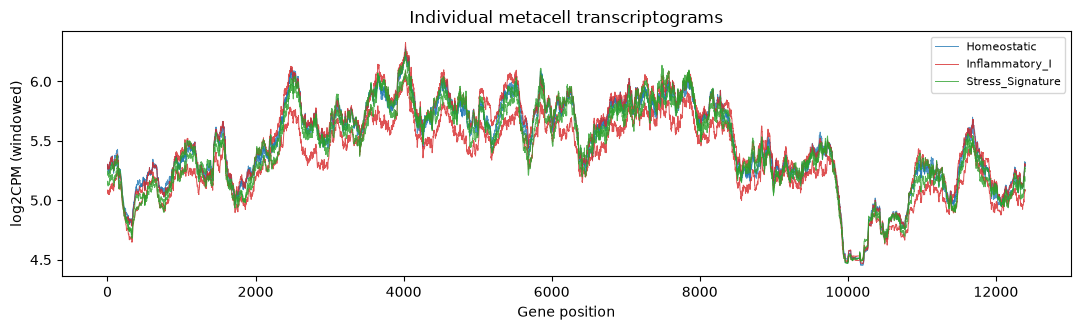

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.4))
np.random.seed(0)
for state, color in zip(["Homeostatic", "Inflammatory_I", "Stress_Signature"],
                        ["#1f77b4", "#d62728", "#2ca02c"]):
    idx = np.where(tg.obs["cell_state"].to_numpy() == state)[0][:2]
    for j, i in enumerate(idx):
        ax.plot(pos, emb[i], color=color, lw=0.7, alpha=0.8,
                label=state if j == 0 else None)
ax.set_xlabel("Gene position"); ax.set_ylabel("log2CPM (windowed)")
ax.set_title("Individual metacell transcriptograms"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. Comparing states: mean profiles and their difference

Averaging the transcriptogram within a cell state gives a **state signature**. The difference between
two state signatures localises *where* on the proteome they diverge.

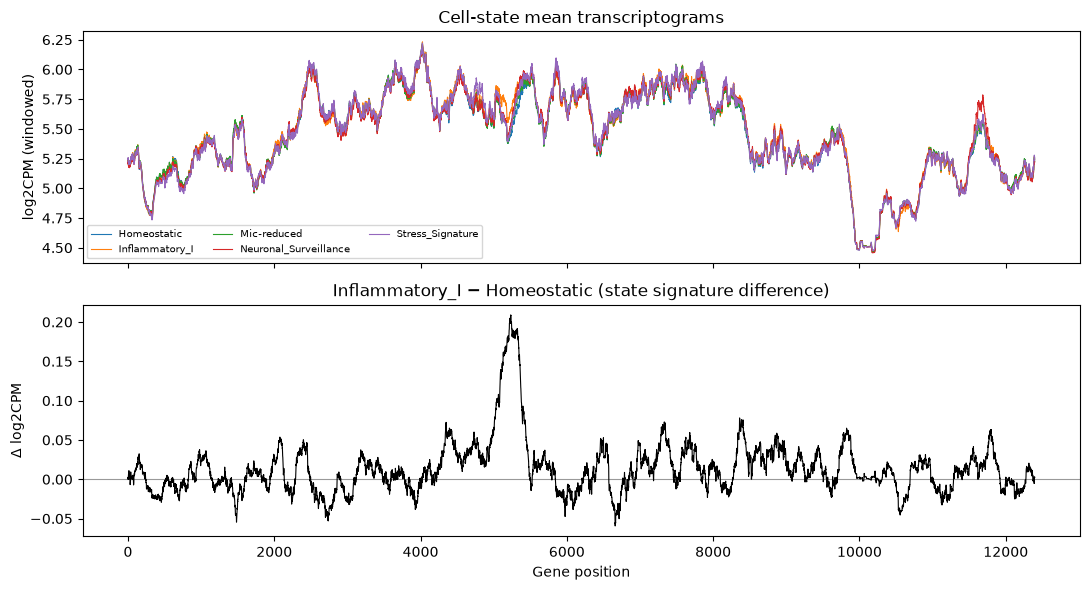

In [3]:
states = tg.obs["cell_state"].cat.categories if hasattr(tg.obs["cell_state"], "cat") \
    else sorted(tg.obs["cell_state"].unique())
state_mean = {s: emb[tg.obs["cell_state"].to_numpy() == s].mean(0) for s in states}

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for s in states:
    axes[0].plot(pos, state_mean[s], lw=0.8, label=s)
axes[0].set_ylabel("log2CPM (windowed)"); axes[0].set_title("Cell-state mean transcriptograms")
axes[0].legend(fontsize=7, ncol=3)

d = state_mean["Inflammatory_I"] - state_mean["Homeostatic"]
axes[1].axhline(0, color="0.6", lw=0.8)
axes[1].plot(pos, d, color="k", lw=0.8)
axes[1].set_xlabel("Gene position")
axes[1].set_ylabel("Δ log2CPM")
axes[1].set_title("Inflammatory_I − Homeostatic (state signature difference)")
plt.tight_layout(); plt.show()

## 3. Metacell–metacell similarity in systems space

Correlating the transcriptograms (over mapped positions) and ordering metacells by state shows that
metacells group by cell state — i.e. the transcriptogram is a coherent per-metacell signature.

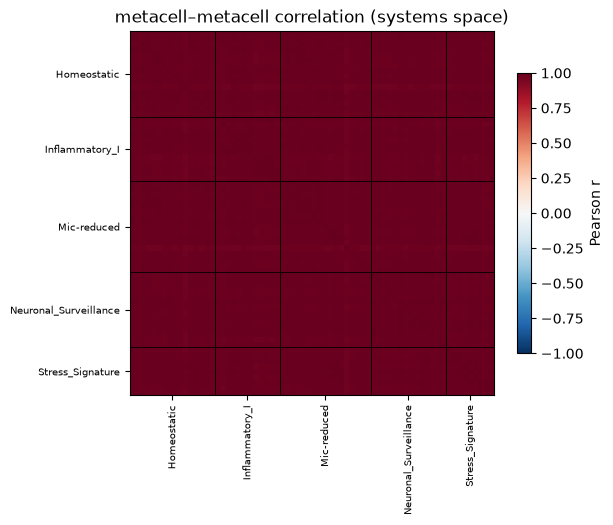

In [4]:
E = emb[:, present]
C = np.corrcoef(E)
order = np.argsort(tg.obs["cell_state"].astype(str).to_numpy(), kind="stable")
Co = C[order][:, order]
lab = tg.obs["cell_state"].astype(str).to_numpy()[order]

fig, ax = plt.subplots(figsize=(6.2, 5.4))
im = ax.imshow(Co, cmap="RdBu_r", vmin=-1, vmax=1)
# state block boundaries
bounds = np.where(lab[1:] != lab[:-1])[0] + 1
for b in bounds:
    ax.axhline(b - 0.5, color="k", lw=0.6); ax.axvline(b - 0.5, color="k", lw=0.6)
centers = [(np.where(lab == s)[0].mean()) for s in pd.unique(lab)]
ax.set_xticks(centers); ax.set_xticklabels(pd.unique(lab), rotation=90, fontsize=7)
ax.set_yticks(centers); ax.set_yticklabels(pd.unique(lab), fontsize=7)
ax.set_title("metacell–metacell correlation (systems space)")
fig.colorbar(im, ax=ax, shrink=0.7, label="Pearson r")
plt.tight_layout(); plt.show()

## 4. Highly variable systems (unsupervised divergence)

Where do metacells diverge most, regardless of labels? Per-position **standard deviation across
metacells** along the ordering. Contiguous high-SD stretches are *highly variable systems* — the
transcriptogram analog of highly variable genes (a ranking, not a formal test).

highly-divergent positions: 1163  ->  8 regions


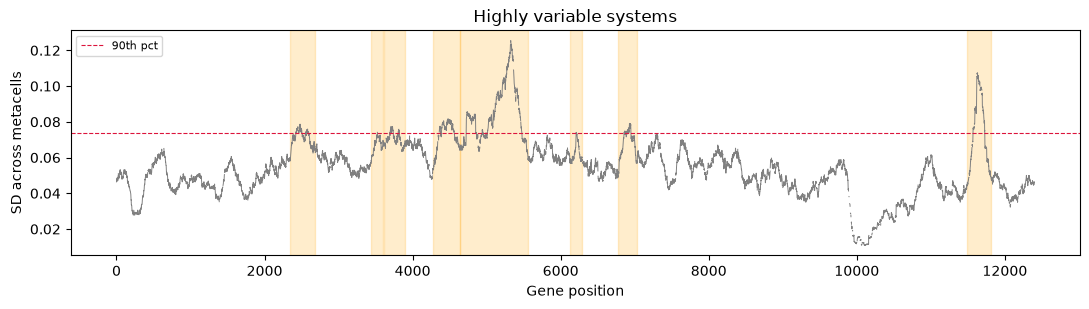

In [5]:
sd = emb.std(0)
sd_present = np.where(present, sd, np.nan)
thr = np.nanquantile(sd_present, 0.90)          # top 10% most-divergent positions
hv = present & (sd >= thr)
hv_regions = sctg.tl.identify_clusters(np.flatnonzero(hv), radius=radius,
                                       n_positions=tg.n_vars, periodic=True)
print(f"highly-divergent positions: {int(hv.sum())}  ->  {hv_regions.n_clusters} regions")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(pos, sd_present, color="0.5", lw=0.7)
for lo, hi in hv_regions.intervals:
    ax.axvspan(lo, hi, color="orange", alpha=0.2)
ax.axhline(thr, color="crimson", lw=0.8, ls="--", label="90th pct")
ax.set_xlabel("Gene position"); ax.set_ylabel("SD across metacells")
ax.set_title("Highly variable systems"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Testing regions that diverge across cell states

`sctg.tl.divergent_systems` turns divergence into a proper test: at each window position it fits an
**NB gamma mixed model** on the window pseudo-counts with cell state as a multi-level factor and
**donor as a random effect**, Wald-tests each level, and combines them with **ACAT** into one omnibus
"does any state differ here" p-value. Significant positions are grouped into **regions** — the unit of
inference (positions are overlapping windows).

This is the count-based, donor-aware version of the descriptive ANOVA screen; the random effect keeps
metacells from the same donor from being treated as independent. (The factor must vary *within*
donors, which cell state does.)

In [6]:
sctg.tl.divergent_systems(tg, group_key="cell_state", donor_key="donor", verbose=False)
info = tg.uns["divergent_systems"]
vtab = tg.varm["divergent_systems_cell_state"]
print(f"levels: {info['levels']}")
print(f"divergent positions (padj<=0.05): {info['n_divergent']}  ->  {info['n_regions']} regions")

levels: ['Homeostatic', 'Inflammatory_I', 'Mic-reduced', 'Neuronal_Surveillance', 'Stress_Signature']
divergent positions (padj<=0.05): 2417  ->  10 regions


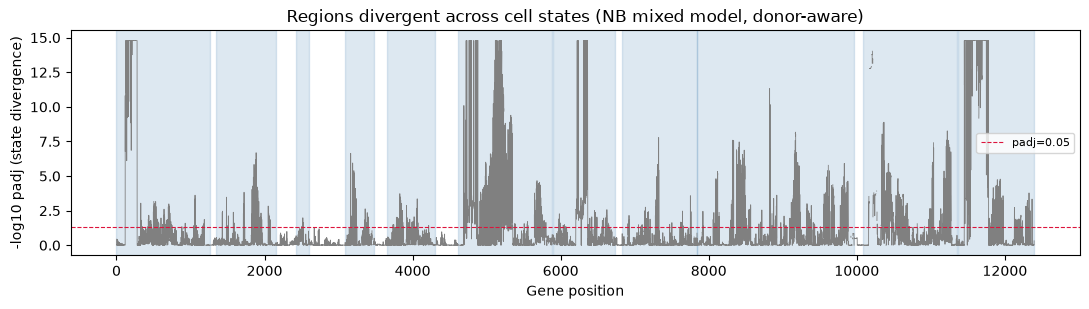

In [7]:
padj = vtab["pAdj"].to_numpy()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(pos, -np.log10(np.where(present, padj, np.nan)), color="0.5", lw=0.6)
for lo, hi in info["regions"]:
    ax.axvspan(lo, hi, color="steelblue", alpha=0.18)
ax.axhline(-np.log10(0.05), color="crimson", lw=0.8, ls="--", label="padj=0.05")
ax.set_xlabel("Gene position"); ax.set_ylabel("-log10 padj (state divergence)")
ax.set_title("Regions divergent across cell states (NB mixed model, donor-aware)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Top divergent regions and their genes

Rank regions by mean `max_abs_logFC` (the largest state effect there) and list representative genes —
candidate system-level axes of microglial heterogeneity.

In [8]:
sym = tg.var["symbol"].to_numpy() if "symbol" in tg.var else tg.var["protein"].to_numpy()
eff = vtab["max_abs_logFC"].to_numpy()
isv = vtab["is_divergent"].to_numpy()
rows = []
for lo, hi in info["regions"]:
    sl = slice(lo, hi + 1)
    top = [g for _, g in sorted(zip(np.nan_to_num(eff[sl]), sym[sl]), reverse=True)
           if isinstance(g, str) and g][:8]
    rows.append((lo, hi, hi - lo + 1, int(np.nansum(isv[sl])),
                 round(float(np.nanmean(eff[sl])), 3), ", ".join(top)))
region_tbl = (pd.DataFrame(rows, columns=["start", "end", "n_pos", "n_divergent",
                                          "mean_max_abs_logFC", "top_genes"])
                .sort_values("mean_max_abs_logFC", ascending=False).reset_index(drop=True))
region_tbl.to_csv(RES / "divergent_systems_cellstate.csv", index=False)
region_tbl.head(10)

,start,end,n_pos,n_divergent,mean_max_abs_logFC,top_genes
0,11372,12395,1024,439,0.279,"NDUFA1, NDUFA2, NDUFA9, NDUFB5, NDUFB9, NDUFB1..."
1,0,1268,1269,278,0.179,"KRT75, KRT37, KRT20, KRT16, KRT86, KRT72, KRT3..."
2,10080,11351,1272,420,0.165,"OR6S1, OR5W2, OR51B5, OR5J2, OR7D4, OR6C6, OR6..."
3,4612,5880,1269,516,0.139,"HIKESHI, HSPA12A, HSPA6, KCTD15, PPP2R2C, HSF1..."
4,5890,6730,841,215,0.114,"AKT3, AKT2, IFNA14, IFNA21, IFNA16, IFNA10, TU..."
5,7841,9960,2120,311,0.081,"MYLK3, TPM2, NECTIN4, PVR, AMELX, RTKN, VSIG4,..."
6,1349,2156,808,82,0.061,"CSAD, ANPEP, GGT5, GGT1, GPX4, GABRA2, GABRG3,..."
7,3081,3484,404,43,0.058,"GINS1, CHTF8, TICRR, TRIM13, PSMB10, RECQL4, B..."
8,3655,4297,643,68,0.056,"PHF1, SYCE3, SYCP2, RNF43, ZNRF3, RYBP, MORF4L..."
9,6829,7840,1012,42,0.050,"LYN, CTNNA1, ARHGEF11, RALGDS, DENND4B, ARHGEF..."


## Summary

- The per-metacell transcriptogram is a **smooth, interpretable systems profile**; metacells cluster
  by cell state in this space (§3), so it is a useful embedding for clustering / trajectory / feature
  extraction.
- **Highly variable systems** (§4) rank where metacells diverge without labels.
- `sctg.tl.divergent_systems` (§5) turns divergence into inference — a donor-aware NB mixed-model test
  of *any* difference across cell states per position, grouped into regions, with `logFC` effect sizes
  and gene lists; the region table is saved to `results/`.
- Everything reads from the standard AnnData (`tg.layers['transcriptogram']`, `tg.var`, `tg.obs`); the
  divergence outputs are plain arrays you can drop back into `tg.var` or feed to enrichment.